# LexiFlow — Dictionary Data Research

## Notebook 01: Source Audit

**Project:** LexiFlow  
**Stage:** Data Research & Feasibility  
**Data Source:** Kaikki / Russian Wiktionary  
**Author:** Elizaveta Lipchanskaya

---

## 0. Introduction and Research Objectives

The objective of this research is to explore the raw dictionary data, understand its structure, and determine how it aligns with LexiFlow's data requirements.

### Research Questions

1. What constitutes an individual entry: a word, a part of speech, or a particular meaning?
2. Can the same word appear in multiple lines of the dataset?
3. Where and how are translations and definitions stored?
4. How are phrasal verbs and idioms represented?
5. Which fields are mandatory, and which may be missing or empty?
6. How are usage examples associated with particular word meanings?

The results of this research will help us design the data model and architecture to be used during application development.

## 1. Data Source Documentation

### 1.1. Wiktionary

Wiktionary is a free, collaborative, multilingual online dictionary.
It provides definitions, translations, pronunciations, grammatical
information, usage examples, and other lexical information.

### 1.2. Kaikki

Kaikki is a platform that provides structured, machine-readable
dictionary data extracted from different language editions of
Wiktionary using Wiktextract.

The extracted datasets are available for browsing and downloading
and are updated regularly.

### 1.3. Wiktextract

Wiktextract is a Python package designed to extract structured
lexical information from Wiktionary data dumps.

Depending on the source edition and the availability of information,
it can extract:

- Definitions and glosses
- Parts of speech
- Translations
- Pronunciations and audio references
- Inflected word forms
- Usage examples and notes
- Synonyms and antonyms
- Related words and expressions
- Alternative forms
- Semantic relationships
- Wikidata identifiers

The availability of these fields in the selected dataset
will be investigated in subsequent tasks.

### 1.4. Dataset Characteristics

| Parameter | Description |
|---|---|
| Data provider | Kaikki |
| Original source | Russian Wiktionary |
| Extraction tool | Wiktextract |
| Target language | English |
| Language of definitions and metadata | Primarily Russian |
| File format | JSONL |
| Published dataset size | 83.0 MB |
| Reported extraction date | 2026-11-01 |
| Data processing status | Post-processed |
| Primary content license | CC BY-SA 4.0 |
| Commercial use | Permitted subject to licensing conditions |

The dataset size and extraction date are based on the
source information observed during the initial research
and will be confirmed during dataset acquisition.

### 1.5. Licensing and Commercial Use

The Wiktextract software is distributed under the MIT License.
However, the license of the extraction software must be
distinguished from the license of the extracted dictionary content.

Wiktionary's original textual content is generally available
under CC BY-SA 4.0, with GFDL licensing also applicable
to eligible material.

Commercial use is permitted under CC BY-SA 4.0,
provided that the relevant licensing requirements are met.

LexiFlow must:

- Provide appropriate attribution to the original contributors.
- Include references to the original sources.
- Provide a link to the applicable license.
- Indicate modifications made to the original content.
- Distribute adapted CC BY-SA content under the same
  or a compatible license.
- Verify additional licensing conditions for externally
  sourced content, images, and audio recordings.

The dictionary content and the application's source code
should be treated as separate components when assessing
licensing requirements.

The final licensing assessment must be completed before
the dataset is distributed as part of LexiFlow.

### 1.6. References

- Russian Wiktionary: https://ru.wiktionary.org/
- Kaikki: https://kaikki.org/
- Selected dataset: https://kaikki.org/ruwiktionary/Английский/index.html
- Wiktextract: https://github.com/tatuylonen/wiktextract
- Wikimedia Terms of Use: https://foundation.wikimedia.org/wiki/Policy:Terms_of_Use
- CC BY-SA 4.0: https://creativecommons.org/licenses/by-sa/4.0/

## 2. Technical Research: JSON and JSONL

### 2.1. Theoretical Background

In [1]:
import json
import pandas as pd

In [16]:
df=pd.read_json("../data/raw/kaikki.org-dictionary-Английский.jsonl", lines=True, nrows=1000)


In [17]:
df.head(5)

,word,pos,lang_code,lang,sounds,forms,etymology_links,etymology_texts,related,hyphenations,...,antonyms,tags,hypernyms,hyponyms,meronyms,metagrams,anagrams,proverbs,holonyms,coordinate_terms
0,abuse,noun,en,Английский,"[{'ipa': '[əˈbjuːs]', 'raw_tags': ['Великобрит...","[{'form': 'abuses', 'tags': ['plural']}]","[[франц., французский язык], [abuser, abuser#Ф...",[Происходит от франц. abuser «злоупотреблять» ...,"[{'word': 'abuse excuse', 'raw_tags': ['Ближай...",[{'parts': ['abuse']}],...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,abuse,verb,en,Английский,"[{'ipa': '[əˈbjuːz]', 'raw_tags': ['Великобрит...","[{'form': 'abuses', 'tags': ['third-person', '...","[[франц., французский язык], [abuser, abuser#Ф...",[Происходит от франц. abuser «злоупотреблять» ...,NaN,[{'parts': ['abuse']}],...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,activity,noun,en,Английский,"[{'ipa': '[ækˈtɪv.ə.ti]', 'audio': 'en-us-acti...","[{'form': 'activities', 'tags': ['plural']}]","[[лат., латинский язык], [activitas, activitas...","[От лат. activitas «активность», далее из acti...",NaN,"[{'parts': ['ac', 'ti', 'vi', 'ty']}]",...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,smell,noun,en,Английский,"[{'ipa': '[smɛl]', 'audio': 'en-us-smell.ogg',...","[{'form': 'smells', 'tags': ['plural']}]",NaN,[Происходит от :Шаблон:этимология:smell],NaN,[{'parts': ['smell']}],...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,smell,verb,en,Английский,"[{'ipa': '[smɛl]', 'audio': 'en-us-smell.ogg',...","[{'form': 'smells', 'tags': ['third-person', '...",NaN,[Происходит от :Шаблон:этимология:smell],NaN,[{'parts': ['smell']}],...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### 2.2. Initial Data Inspection

In [18]:
df.shape

(1000, 24)

available 1000*24 fields


In [19]:
df.columns

Index(['word', 'pos', 'lang_code', 'lang', 'sounds', 'forms',
       'etymology_links', 'etymology_texts', 'related', 'hyphenations',
       'categories', 'senses', 'derived', 'synonyms', 'antonyms', 'tags',
       'hypernyms', 'hyponyms', 'meronyms', 'metagrams', 'anagrams',
       'proverbs', 'holonyms', 'coordinate_terms'],
      dtype='str')

In [22]:
df.dtypes

word                   str
pos                    str
lang_code              str
lang                   str
sounds              object
forms               object
etymology_links     object
etymology_texts     object
related             object
hyphenations        object
categories          object
senses              object
derived             object
synonyms            object
antonyms            object
tags                object
hypernyms           object
hyponyms            object
meronyms            object
metagrams           object
anagrams            object
proverbs            object
holonyms            object
coordinate_terms    object
dtype: object

In [23]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 24 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   word              1000 non-null   str   
 1   pos               1000 non-null   str   
 2   lang_code         1000 non-null   str   
 3   lang              1000 non-null   str   
 4   sounds            702 non-null    object
 5   forms             512 non-null    object
 6   etymology_links   324 non-null    object
 7   etymology_texts   904 non-null    object
 8   related           229 non-null    object
 9   hyphenations      670 non-null    object
 10  categories        1000 non-null   object
 11  senses            1000 non-null   object
 12  derived           206 non-null    object
 13  synonyms          290 non-null    object
 14  antonyms          102 non-null    object
 15  tags              13 non-null     object
 16  hypernyms         102 non-null    object
 17  hyponyms          27 non-n

In [39]:
df['word'].nunique()

642

In [50]:
df['pos'].value_counts(normalize=True, sort=True).head(10)

pos
noun       0.481
verb       0.264
adj        0.154
adv        0.033
unknown    0.018
phrase     0.018
abbrev     0.008
pron       0.008
prep       0.005
num        0.003
Name: proportion, dtype: float64

In [51]:
df['word'].value_counts().head(10)

word
list       8
fair       6
one        5
retail     5
scale      5
slack      5
bark       5
content    4
tan        4
host       4
Name: count, dtype: int64

In [52]:
from pprint import pprint

In [57]:
pprint(df.iloc[0].to_dict())

{'anagrams': nan,
 'antonyms': nan,
 'categories': [{'kind': 'other',
                 'name': 'Английские существительные',
                 'parents': [],
                 'source': 'w'},
                {'kind': 'other',
                 'name': 'Английский язык',
                 'parents': [],
                 'source': 'w'},
                {'kind': 'other',
                 'name': 'Нет сведений о составе слова',
                 'parents': [],
                 'source': 'w'},
                {'kind': 'other',
                 'name': 'Омонимы/en',
                 'parents': [],
                 'source': 'w'},
                {'kind': 'other',
                 'name': 'Оскорбления/en',
                 'parents': [],
                 'source': 'w'},
                {'kind': 'other',
                 'name': 'Преступления/en',
                 'parents': [],
                 'source': 'w'},
                {'kind': 'other',
                 'name': 'Статьи с 2 омонимами/en',
  

In [80]:
senses=df['senses'].iloc[0]

In [81]:
len(senses)


4

In [82]:
pprint(senses)

[{'examples': [{'bold_text_offsets': [[5, 10]],
                'bold_translation_offsets': [[0, 15]],
                'text': 'Drug abuse.',
                'translation': 'Злоупотребление наркотиками.'}],
  'glosses': ['злоупотребление'],
  'id': 'ru-abuse-en-noun-RmyNcfOb'},
 {'glosses': ['оскорбление, брань'], 'id': 'ru-abuse-en-noun-gAIIKbzk'},
 {'glosses': ['плохое обращение'], 'id': 'ru-abuse-en-noun-uQBoi~bL'},
 {'glosses': ['неправильное употребление'], 'id': 'ru-abuse-en-noun-GGOpBwrr'}]


In [83]:
type(senses[0])

dict

In [84]:
df_full = pd.read_json(
    "../data/raw/kaikki.org-dictionary-Английский.jsonl",
    lines=True
)

print("Total records:", len(df_full))
print("Unique words:", df_full["word"].nunique())
print("Total fields:", len(df_full.columns))

Total records: 72487
Unique words: 67290
Total fields: 25


In [85]:
coverage = pd.DataFrame({
    "Available": df_full.notna().sum(),
    "Missing": df_full.isna().sum(),
    "Coverage (%)": df_full.notna().mean() * 100
})

coverage.sort_values(
    "Coverage (%)", ascending=False
).round(2)

,Available,Missing,Coverage (%)
word,72487,0,100.00
pos,72487,0,100.00
lang_code,72487,0,100.00
lang,72487,0,100.00
categories,72487,0,100.00
senses,72487,0,100.00
etymology_texts,59166,13321,81.62
hyphenations,55184,17303,76.13
hypernyms,18516,53971,25.54
sounds,15088,57399,20.81


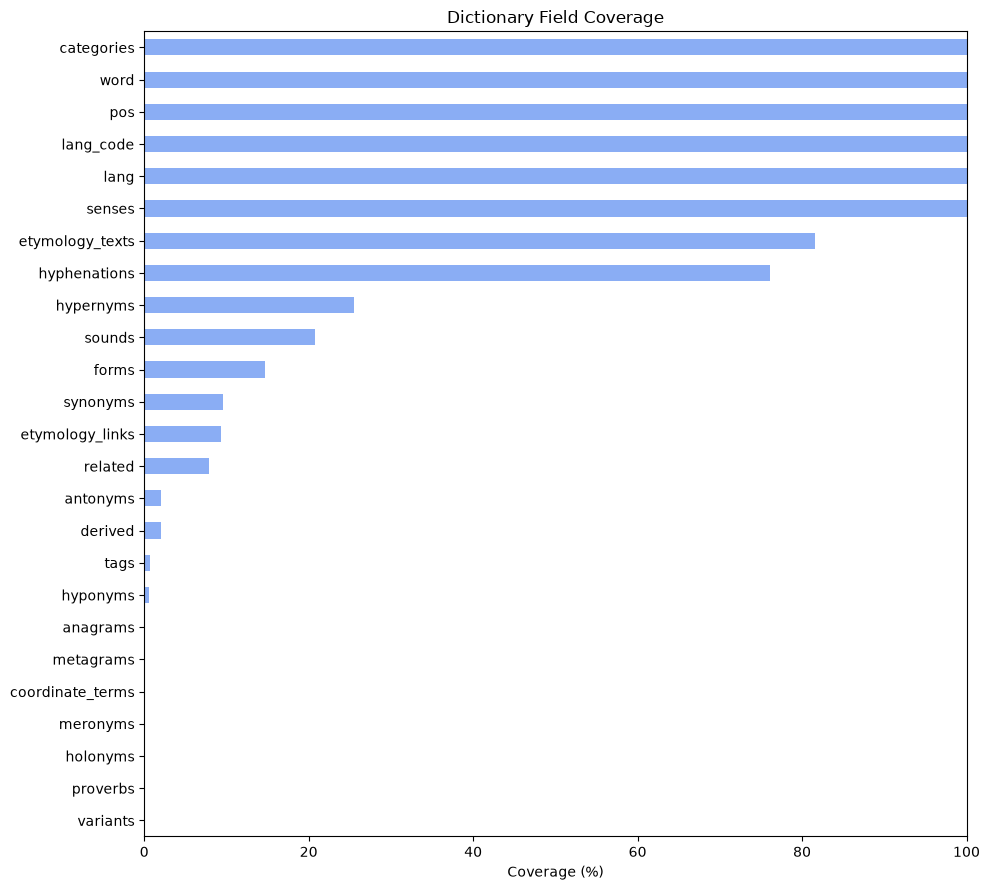

In [86]:
import matplotlib.pyplot as plt

coverage["Coverage (%)"].sort_values().plot(
    kind="barh",
    figsize=(10, 9),
    color="#8aadf4"
)

plt.title("Dictionary Field Coverage")
plt.xlabel("Coverage (%)")
plt.xlim(0, 100)
plt.tight_layout()
plt.show()

In [87]:
from collections import Counter

sense_fields = Counter()

for senses_list in df_full["senses"]:
    if isinstance(senses_list, list):
        for sense in senses_list:
            if isinstance(sense, dict):
                sense_fields.update(sense.keys())

total_senses = sum(
    len(x) for x in df_full["senses"]
    if isinstance(x, list)
)

print("Total senses:", total_senses)

sense_coverage = pd.DataFrame({
    "Count": pd.Series(sense_fields)
})

sense_coverage["Coverage (%)"] = (
    sense_coverage["Count"] / total_senses * 100
)

sense_coverage.sort_values(
    "Count", ascending=False
).round(2)

Total senses: 104902


,Count,Coverage (%)
id,104902,100.00
glosses,97192,92.65
examples,22386,21.34
categories,20765,19.79
tags,8024,7.65
raw_tags,571,0.54
form_of,169,0.16
topics,9,0.01


### 3.2. Preliminary Findings

The dataset contains 72,487 dictionary records,
representing 67,290 unique word and expression spellings
and 104,902 individual senses.

The dataset includes 25 top-level fields and supports
a hierarchical representation of lexical information.

All senses contain an identifier, while 92.65% contain
glosses and 21.34% contain usage examples.

The initial analysis indicates that the dataset is
a promising candidate for the core LexiFlow dictionary.

However, the limited coverage of usage examples,
pronunciation data, and additional linguistic metadata
suggests that supplementary data sources may be required.

Field presence does not guarantee content quality,
completeness, or translation accuracy. Further analysis
is required to determine the number of usable entries.

## 4. LexiFlow Data Suitability Assessment

### 4.1. Sense-Level Data Normalization

In [88]:
df_senses = (
    df_full[["word", "pos", "lang_code", "senses"]]
    .explode("senses")
    .reset_index(drop=True)
)

df_senses = df_senses[
    df_senses["senses"].apply(
        lambda x: isinstance(x, dict)
    )
].reset_index(drop=True)

sense_data = pd.json_normalize(df_senses["senses"])

df_senses = pd.concat(
    [
        df_senses.drop(columns="senses"),
        sense_data
    ],
    axis=1
)

print("Shape:", df_senses.shape)

df_senses.head()

Shape: (104902, 11)


,word,pos,lang_code,glosses,examples,id,categories,tags,raw_tags,topics,form_of
0,abuse,noun,en,[злоупотребление],"[{'text': 'Drug abuse.', 'bold_text_offsets': ...",ru-abuse-en-noun-RmyNcfOb,NaN,NaN,NaN,NaN,NaN
1,abuse,noun,en,"[оскорбление, брань]",NaN,ru-abuse-en-noun-gAIIKbzk,NaN,NaN,NaN,NaN,NaN
2,abuse,noun,en,[плохое обращение],NaN,ru-abuse-en-noun-uQBoi~bL,NaN,NaN,NaN,NaN,NaN
3,abuse,noun,en,[неправильное употребление],NaN,ru-abuse-en-noun-GGOpBwrr,NaN,NaN,NaN,NaN,NaN
4,abuse,verb,en,[злоупотреблять],NaN,ru-abuse-en-verb-p3uF-PaC,NaN,NaN,NaN,NaN,NaN


In [89]:
print("Total senses:", len(df_senses))
print("Unique IDs:", df_senses["id"].nunique())
print("Missing IDs:", df_senses["id"].isna().sum())
print("Duplicate IDs:", df_senses["id"].duplicated().sum())

Total senses: 104902
Unique IDs: 104900
Missing IDs: 0
Duplicate IDs: 2


In [90]:
def has_text(value):
    return isinstance(value, str) and bool(value.strip())


def has_gloss(value):
    return isinstance(value, list) and any(
        has_text(item) for item in value
    )


def has_example(value):
    return isinstance(value, list) and any(
        isinstance(item, dict)
        and has_text(item.get("text"))
        for item in value
    )


def has_translated_example(value):
    return isinstance(value, list) and any(
        isinstance(item, dict)
        and has_text(item.get("text"))
        and has_text(item.get("translation"))
        for item in value
    )


df_senses["has_gloss"] = df_senses["glosses"].apply(
    has_gloss
)

df_senses["has_example"] = df_senses["examples"].apply(
    has_example
)

df_senses["has_translated_example"] = (
    df_senses["examples"].apply(has_translated_example)
)

In [91]:
metrics = [
    "has_gloss",
    "has_example",
    "has_translated_example"
]

content_coverage = pd.DataFrame({
    "Count": df_senses[metrics].sum(),
    "Coverage (%)": df_senses[metrics].mean() * 100
})

content_coverage.round(2)

,Count,Coverage (%)
has_gloss,97192,92.65
has_example,22386,21.34
has_translated_example,20975,19.99


In [92]:
basic_senses = df_senses[
    df_senses["has_gloss"]
]

extended_senses = df_senses[
    df_senses["has_gloss"]
    & df_senses["has_example"]
]

translated_senses = df_senses[
    df_senses["has_gloss"]
    & df_senses["has_translated_example"]
]

summary = pd.DataFrame({
    "Senses": [
        len(basic_senses),
        len(extended_senses),
        len(translated_senses)
    ],
    "Unique words": [
        basic_senses["word"].nunique(),
        extended_senses["word"].nunique(),
        translated_senses["word"].nunique()
    ]
}, index=[
    "With gloss",
    "With gloss and example",
    "With gloss and translated example"
])

summary

,Senses,Unique words
With gloss,97192,59646
With gloss and example,22386,17464
With gloss and translated example,20975,16647


In [93]:
df_senses[
    df_senses["id"].duplicated(keep=False)
].sort_values("id")

,word,pos,lang_code,glosses,examples,id,categories,tags,raw_tags,topics,form_of,has_gloss,has_example,has_translated_example
6371,as,conj,en,[как],"[{'text': 'white as snow', 'bold_text_offsets'...",ru-as-en-conj-F-6-NPQx1,NaN,NaN,[вводит обстоятельственные обороты сравнения],NaN,NaN,True,True,True
6374,as,conj,en,[как],"[{'text': 'as you know', 'bold_text_offsets': ...",ru-as-en-conj-F-6-NPQx1,NaN,NaN,[употребляется во вводных словах и предложениях],NaN,NaN,True,True,True
84305,rase,noun,en,[вариант race],NaN,ru-rase-en-noun-~md~3Jm-1,NaN,NaN,NaN,NaN,NaN,True,False,False
84306,rase,noun,en,[вариант race],NaN,ru-rase-en-noun-~md~3Jm-1,NaN,NaN,NaN,NaN,NaN,True,False,False


### 4.5. Findings

All 104,902 lexical senses were successfully normalized
into a structured DataFrame without record loss.

The content availability analysis identified:

- 59,646 unique words with at least one non-empty gloss.
- 17,464 unique words with a gloss and a usage example.
- 16,647 unique words with a gloss and a translated example.

The dataset contains 104,900 unique sense identifiers,
with no missing identifiers and two duplicate occurrences.

The results demonstrate substantial potential for building
the core LexiFlow dictionary. However, content availability
does not guarantee linguistic accuracy or completeness.

Duplicate identifiers must be addressed during ETL processing.

### 4.6. Duplicate Identifier Analysis

Two duplicate identifier groups were identified:

- "as": the same source identifier is associated with
  different usage contexts and examples.
- "rase": two apparently identical records share
  the same source identifier.

Source identifiers cannot be used directly as primary
keys without additional validation.

LexiFlow should maintain internal unique identifiers
while preserving original source identifiers for
data provenance.

Duplicate resolution must distinguish between redundant
records and distinct lexical meanings.